# 06 — Análisis comparativo inferencial: ¿qué distingue a quienes participan?

**Etapa CRISP-DM:** Análisis / evaluación · **OE4 / OE5**

## Objetivo
Producir los **artefactos del informe LaTeX** (figuras PNG, tablas CSV y `.tex`)
del análisis comparativo participantes vs. no participantes, usando **el mismo
cálculo** que alimenta el dashboard (`src.comparative_stats.compute_comparative`).
Este notebook **no recalcula** estadísticos: los lee de `comp` y solo **dibuja,
tabula, narra y verifica**.

## Principios
- **Fuente única de verdad (RNF-1):** las cifras del informe salen del mismo dict
  que `data.json`. El redondeo se aplica una sola vez en Python (dict
  `comparative_stats.DECIMALES`).
- **Efecto sobre significancia:** con $N$ grande casi todo es "significativo"; la
  lectura se ancla en el **tamaño del efecto** (d de Cohen, V de Cramér).
- **Privacidad (RNF-3):** solo agregados; categorías con $n < 30$ suprimidas; sin
  mínimos/máximos crudos (los boxplots usan los bigotes de Tukey precalculados).
- **Consistencia verificada (M1):** la última celda **falla el build** si las
  cifras renderizadas (CSV/.tex) divergen de `comp` o de `data.json`.

In [1]:
import sys, os
from pathlib import Path
# Permitir importar el paquete src desde notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 12

from src import config, utils, internationalization as intl
print('Entorno listo. Raiz del proyecto:', ROOT)

Entorno listo. Raiz del proyecto: C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO


In [2]:
# Dependencias específicas del notebook: cálculo (fuente única) y formateo LaTeX.
import shutil
import json
import csv
from src import comparative_stats as cs
from nb_helpers import df_to_latex_booktabs

# Rutas ABSOLUTAS desde config (el kernel corre con cwd=notebooks/).
LATEX_DIR = config.ROOT_DIR / 'latex'
LATEX_TABLAS = LATEX_DIR / 'tablas'
LATEX_FIG = LATEX_DIR / 'figuras'
LATEX_TABLAS.mkdir(parents=True, exist_ok=True)
LATEX_FIG.mkdir(parents=True, exist_ok=True)
DATA_JSON = config.ROOT_DIR / 'dashboard' / 'public' / 'data.json'
print('Tablas .tex ->', LATEX_TABLAS)
print('Figuras     ->', LATEX_FIG)

Tablas .tex -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\latex\tablas
Figuras     -> C:\Users\JUAN DAVID\Documents\UNIANDES\8VO SEMESTRE\PROY GRADO 2026-2\TRAVAIL\PROY-GRADO\latex\figuras


## 1. Cálculo comparativo (fuente única)
Se carga el dataset analítico y se llama a `compute_comparative` **una sola vez**.
El dict `comp` es idéntico al que `export_dashboard` escribe en `data.json`.

In [3]:
df = pd.read_parquet(config.ANALYTIC_DATASET)
comp = cs.compute_comparative(df, 'pregrado')

meta = comp['meta']
print('Alcance:', meta['alcance'])
print(f"Participantes: {meta['n_part']:,} | No participantes: {meta['n_no']:,} "
      f"| Tasa base: {meta['tasa_base_pct']}%")

# Numéricas calculables ordenadas por tamaño de efecto |d|.
num_calc = [x for x in comp['numericas'] if x['cohen_d'] is not None]
num_orden = sorted(num_calc, key=lambda x: abs(x['cohen_d']), reverse=True)
print('\nNuméricas por |d| (top):')
for x in num_orden[:6]:
    print(f"  {x['label']:<30} d={x['cohen_d']:+.2f} ({x['magnitud_d']})")

cat_calc = [x for x in comp['categoricas'] if x['cramers_v'] is not None]
print('\nCategóricas por V de Cramér:')
for x in sorted(cat_calc, key=lambda x: -x['cramers_v']):
    print(f"  {x['label']:<22} V={x['cramers_v']:.2f} ({x['magnitud_v']})")

Alcance: Pregrado
Participantes: 5,821 | No participantes: 134,601 | Tasa base: 4.15%

Numéricas por |d| (top):
  Número de opciones inscritas   d=+1.07 (grande)
  Créditos aprobados (total)     d=+0.76 (mediano)
  Percentil de PGA (programa)    d=+0.75 (mediano)
  Percentil de PGA (nivel)       d=+0.71 (mediano)
  PGA (último)                   d=+0.68 (mediano)
  PGA promedio histórico         d=+0.67 (mediano)

Categóricas por V de Cramér:
  Estado académico       V=0.23 (mediano)
  Estrato social         V=0.15 (pequeño)
  Facultad               V=0.14 (pequeño)
  Tipo de admisión       V=0.08 (trivial)
  Género                 V=0.02 (trivial)


### Interpretación
El cuadro anterior resume el núcleo del análisis: las diferencias más grandes
entre participantes y no participantes se dan en variables de **trayectoria y
desempeño**, mientras que las asociaciones categóricas de mayor interés para la
equidad son las de **estrato social** y **género**. Todo lo que sigue (figuras,
tablas y narrativa) se construye desde este mismo `comp`.

## 2. Figuras
Tres figuras, todas dibujadas desde `comp` (sin recomputar nada):
boxplots participa vs. no de las numéricas de mayor efecto, barras del d de Cohen
y barras de la V de Cramér.

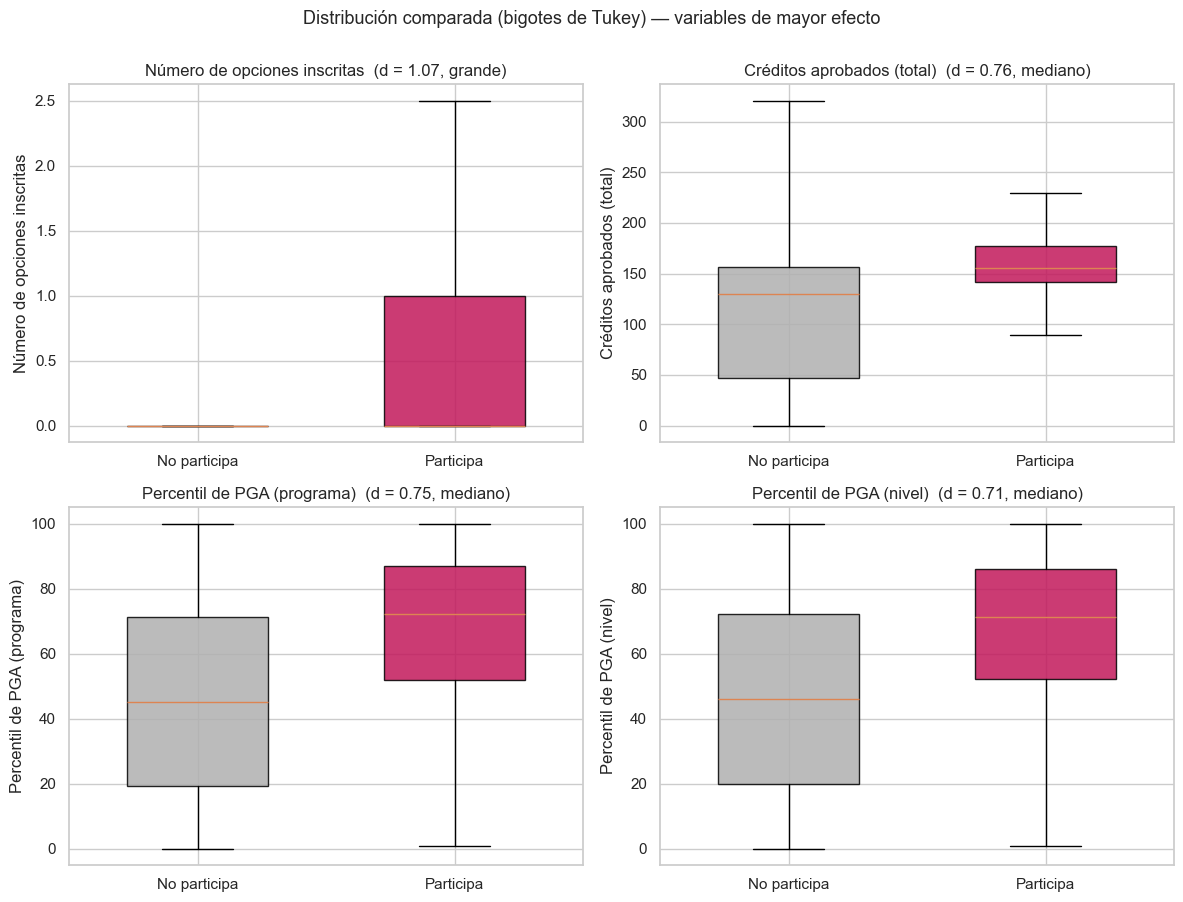

In [4]:
# --- Figura 1: rejilla de boxplots (bigotes de Tukey precalculados en comp) ---
# Se usan EXCLUSIVAMENTE los 5 números de comp (q1, mediana, q3, bigotes): no se
# recalculan cuantiles ni se exponen min/max crudos (RNF-3).
top_box = num_orden[:4]
ncols = 2
nrows = int(np.ceil(len(top_box) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4.5 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, x in zip(axes, top_box):
    stats_bxp = [
        {'label': 'No participa', 'med': x['mediana_no'], 'q1': x['q1_no'],
         'q3': x['q3_no'], 'whislo': x['whisker_low_no'], 'whishi': x['whisker_high_no'],
         'fliers': []},
        {'label': 'Participa', 'med': x['mediana_part'], 'q1': x['q1_part'],
         'q3': x['q3_part'], 'whislo': x['whisker_low_part'], 'whishi': x['whisker_high_part'],
         'fliers': []},
    ]
    bp = ax.bxp(stats_bxp, showfliers=False, patch_artist=True, widths=0.55)
    for parche, color in zip(bp['boxes'], ['#b0b0b0', '#c2185b']):
        parche.set_facecolor(color)
        parche.set_alpha(0.85)
    ax.set_title(f"{x['label']}  (d = {x['cohen_d']:.2f}, {x['magnitud_d']})")
    ax.set_ylabel(x['label'])
# Ocultar ejes sobrantes si los hubiera.
for ax in axes[len(top_box):]:
    ax.set_visible(False)
fig.suptitle('Distribución comparada (bigotes de Tukey) — variables de mayor efecto',
             fontsize=13, y=1.00)
plt.tight_layout()
utils.save_fig(fig, 'fig_comparativo_boxplots.png')
plt.show()

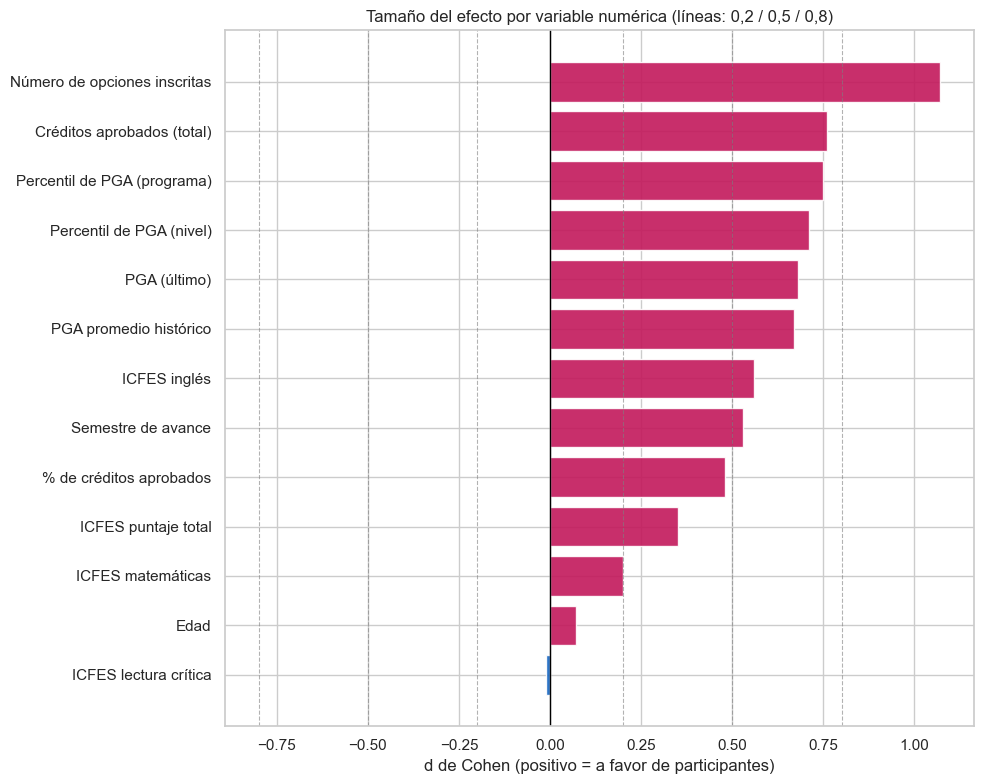

In [5]:
# --- Figura 2: barras horizontales del d de Cohen, ordenadas por |d| ---
num_plot = sorted(num_calc, key=lambda x: abs(x['cohen_d']))
labels = [x['label'] for x in num_plot]
dvals = [x['cohen_d'] for x in num_plot]
colores = ['#c2185b' if d >= 0 else '#1565c0' for d in dvals]

fig, ax = plt.subplots(figsize=(10, 0.5 * len(num_plot) + 1.5))
ax.barh(labels, dvals, color=colores, alpha=0.9)
# Bandas de magnitud de Cohen (0.2 / 0.5 / 0.8) en ambos signos.
for umbral in (0.2, 0.5, 0.8):
    for signo in (1, -1):
        ax.axvline(signo * umbral, color='gray', ls='--', lw=0.8, alpha=0.6)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('d de Cohen (positivo = a favor de participantes)')
ax.set_title("Tamaño del efecto por variable numérica (líneas: 0,2 / 0,5 / 0,8)")
plt.tight_layout()
utils.save_fig(fig, 'fig_comparativo_cohend.png')
plt.show()

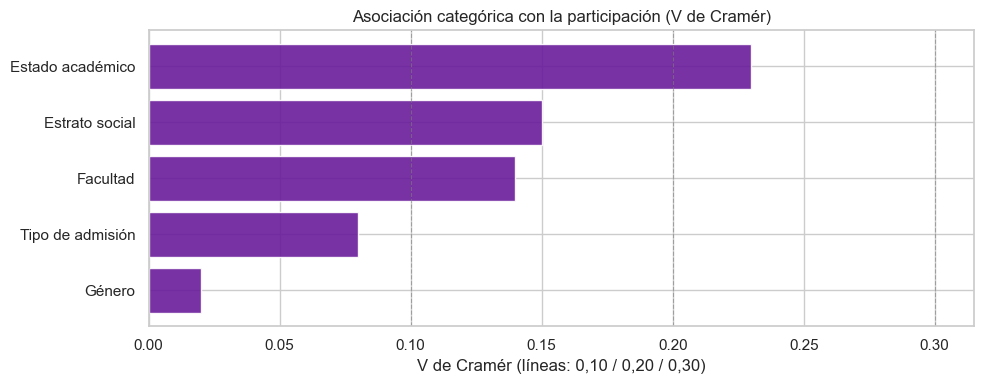

In [6]:
# --- Figura 3: barras de la V de Cramér por categórica, con bandas de magnitud ---
cat_plot = sorted(cat_calc, key=lambda x: x['cramers_v'])
clabels = [x['label'] for x in cat_plot]
vvals = [x['cramers_v'] for x in cat_plot]

fig, ax = plt.subplots(figsize=(10, 0.5 * len(cat_plot) + 1.5))
ax.barh(clabels, vvals, color='#6a1b9a', alpha=0.9)
for umbral in (0.10, 0.20, 0.30):
    ax.axvline(umbral, color='gray', ls='--', lw=0.8, alpha=0.6)
ax.set_xlabel('V de Cramér (líneas: 0,10 / 0,20 / 0,30)')
ax.set_title('Asociación categórica con la participación (V de Cramér)')
plt.tight_layout()
utils.save_fig(fig, 'fig_comparativo_cramersv.png')
plt.show()

### Interpretación
Los boxplots hacen visible el desplazamiento de las medianas entre grupos para las
variables de mayor efecto; las barras del d de Cohen ordenan ese efecto y su signo
(positivo = a favor de participantes), y las bandas marcan los umbrales
convencionales. La V de Cramér sitúa las asociaciones categóricas: el estrato
social destaca como la de mayor magnitud entre las de equidad.

## 3. Tablas (CSV + .tex booktabs)
Cada tabla se escribe dos veces: un **CSV** en `reports/tables/` (fuente neutra,
sin coma decimal) y un **`.tex` booktabs** en `latex/tablas/` (lo que el informe
`\input`). Ambos se formatean con el **mismo** dict `cs.DECIMALES`, de modo que la
cifra publicada es idéntica (base de la verificación M1).

In [7]:
# --- Tabla numérica ---
def _fila_num(x):
    return {
        'label': x['label'],
        'media_no': x['media_no'],
        'media_part': x['media_part'],
        'dif_medias': x['dif_medias'],
        'ic95_low': x['ic95_low'],
        'ic95_high': x['ic95_high'],
        'cohen_d': x['cohen_d'],
        'magnitud_d': x['magnitud_d'],
        'p_welch': x['p_welch'],
        'p_mannwhitney': x['p_mannwhitney'],
        'p_ajustada': x['p_ajustada'],
    }

# CSV: orden canónico de comp['numericas'] (contrato estable; la primera fila con
# 'PGA' en la etiqueta es PGA (último), que es la que verifica la coherencia).
df_num_csv = pd.DataFrame([_fila_num(x) for x in comp['numericas'] if x['cohen_d'] is not None])
df_num_csv.to_csv(config.TABLES_DIR / 'comparativo_numericas.csv', index=False, encoding='utf-8')

# .tex: ordenado por |d| (lectura directa del efecto en el informe).
df_num_tex = pd.DataFrame([_fila_num(x) for x in num_orden])

cols_num = [
    ('label', 'Variable'), ('media_no', 'Media no'), ('media_part', 'Media part.'),
    ('dif_medias', 'Dif.'), ('ic95_low', 'IC95 inf.'), ('ic95_high', 'IC95 sup.'),
    ('cohen_d', 'd de Cohen'), ('magnitud_d', 'Magnitud'),
    ('p_welch', 'p (Welch)'), ('p_mannwhitney', 'p (MW)'), ('p_ajustada', 'p ajust.'),
]
tex_num = df_to_latex_booktabs(
    df_num_tex, cols_num, cs.DECIMALES, longtable=True,
    caption='Comparación de variables numéricas (participantes vs. no), ordenadas por tamaño de efecto.',
    label='tab:comparativo-num')
(LATEX_TABLAS / 'comparativo_numericas.tex').write_text(tex_num, encoding='utf-8')
print('comparativo_numericas: CSV (orden canónico) + .tex (orden |d|) OK (', len(df_num_csv), 'filas )')

comparativo_numericas: CSV (orden canónico) + .tex (orden |d|) OK ( 13 filas )


In [8]:
# --- Tabla categórica ---
filas_cat = []
for x in comp['categoricas']:
    filas_cat.append({
        'label': x['label'],
        'chi2': x['chi2'],
        'dof': x['dof'],
        'p': x['p'],
        'cramers_v': x['cramers_v'],
        'magnitud_v': x['magnitud_v'],
        'p_ajustada': x['p_ajustada'],
    })
df_cat = pd.DataFrame(filas_cat)
df_cat.to_csv(config.TABLES_DIR / 'comparativo_categoricas.csv', index=False, encoding='utf-8')

cols_cat = [
    ('label', 'Variable'), ('chi2', 'Chi-cuadrado'), ('dof', 'gl'), ('p', 'p'),
    ('cramers_v', 'V de Cramer'), ('magnitud_v', 'Magnitud'), ('p_ajustada', 'p ajust.'),
]
tex_cat = df_to_latex_booktabs(
    df_cat, cols_cat, cs.DECIMALES, longtable=False,
    caption=None, label=None)
(LATEX_TABLAS / 'comparativo_categoricas.tex').write_text(tex_cat, encoding='utf-8')
print('comparativo_categoricas: CSV + .tex OK (', len(df_cat), 'filas )')

comparativo_categoricas: CSV + .tex OK ( 5 filas )


In [9]:
# --- Tabla logística ---
pred = comp['logistica']['predictores']
filas_log = [{
    'label': p['label'],
    'odds_ratio': p['odds_ratio'],
    'ic95_low': p['ic95_low'],
    'ic95_high': p['ic95_high'],
} for p in pred]
df_log = pd.DataFrame(filas_log)
df_log.to_csv(config.TABLES_DIR / 'comparativo_logistica.csv', index=False, encoding='utf-8')

cols_log = [
    ('label', 'Predictor (z-score)'), ('odds_ratio', 'OR'),
    ('ic95_low', 'IC95 inf.'), ('ic95_high', 'IC95 sup.'),
]
tex_log = df_to_latex_booktabs(
    df_log, cols_log, cs.DECIMALES, longtable=False, caption=None, label=None)
(LATEX_TABLAS / 'comparativo_logistica.tex').write_text(tex_log, encoding='utf-8')
print('comparativo_logistica: CSV + .tex OK (', len(df_log), 'filas )')
print('Modo del modelo:', comp['logistica']['meta_modelo']['modo'],
      '| n efectivo:', comp['logistica']['meta_modelo']['n_efectivo'])

comparativo_logistica: CSV + .tex OK ( 4 filas )
Modo del modelo: multivariado | n efectivo: 31076


## 4. Copia de figuras a `latex/figuras/`
El informe usa `\graphicspath{{figuras/}}`, por lo que las PNG deben estar en
`latex/figuras/`. Se copian desde `reports/figures/` con rutas absolutas.

In [10]:
for png in ['fig_comparativo_boxplots.png', 'fig_comparativo_cohend.png',
            'fig_comparativo_cramersv.png']:
    shutil.copy2(config.FIGURES_DIR / png, LATEX_FIG / png)
    print('copiada ->', (LATEX_FIG / png).name)

copiada -> fig_comparativo_boxplots.png
copiada -> fig_comparativo_cohend.png
copiada -> fig_comparativo_cramersv.png


## 5. Narrativa con cifras interpoladas (M2)
La prosa del informe se **interpola** desde `comp` (misma fuente que la web):
**cero cifras tecleadas a mano**. Se reutiliza `cs.construir_narrativa` para que la
narrativa de la web (`data.json`) y la del informe sean idénticas, y se envuelve en
un breve bloque LaTeX.

In [11]:
# La narrativa ya la construye la fuente única (misma prosa que data.json).
# En data.json va en texto plano (web); para el .tex del informe escapamos los
# caracteres especiales de LaTeX (sobre todo el %, que inicia comentario). Las
# cifras NO cambian: solo se escapa la puntuación de control.
narrativa = comp['meta']['resumen_narrativo']

# Verificación de que cs.construir_narrativa y la narrativa del dict coinciden
# (misma función, mismas cifras): refuerza que web e informe cuentan lo mismo.
assert narrativa == cs.construir_narrativa(comp), \
    'La narrativa del dict no coincide con construir_narrativa (fuente única).'

def _escapar_tex(texto):
    '''Escapa % & # $ _ para LaTeX sin alterar las cifras interpoladas.'''
    for k, v in (('&', r'\&'), ('%', r'\%'), ('#', r'\#'),
                 ('$', r'\$'), ('_', r'\_')):
        texto = texto.replace(k, v)
    return texto

tex_narrativa = (
    "% Narrativa generada automaticamente desde comparative_stats (M2): NO editar a mano.\n"
    "% Cada cifra esta interpolada desde compute_comparative; regenerar actualiza el texto.\n"
    + _escapar_tex(narrativa) + "\n"
)
(LATEX_TABLAS / 'comparativo_narrativa.tex').write_text(tex_narrativa, encoding='utf-8')
print('comparativo_narrativa.tex escrita. Longitud:', len(narrativa), 'caracteres.')
print('\n' + narrativa)

comparativo_narrativa.tex escrita. Longitud: 980 caracteres.

En pregrado (5.821 participantes frente a 134.601 no participantes, tasa base 4,15%), el análisis prioriza el tamaño del efecto sobre la mera significancia estadística, inevitable con muestras tan grandes. Las diferencias de mayor magnitud entre grupos aparecen en número de opciones inscritas (d = 1,07, efecto grande), créditos aprobados (total) (d = 0,76, efecto mediano) y percentil de pga (programa) (d = 0,75, efecto mediano); todas favorecen a quienes participan. La asociación con el estrato social es de magnitud pequeño (V de Cramér = 0,15) (estrato 1 con 0,42% y estrato 6 con 9,48%): persiste un gradiente socioeconómico que debe leerse como brecha de equidad, no como criterio de selección. La asociación con el género es trivial (V de Cramér = 0,02). Todas las relaciones son asociaciones observadas, no relaciones causales; el modelo logístico multivariado se reporta como aproximación (sin p-valores analíticos) y compleme

## 6. Verificación de consistencia (M1)
Esta celda **falla el build** (`python build_notebooks.py 06`) si las cifras que el
informe REALMENTE renderiza divergen de la fuente única. Compara, a la precisión
publicada (`cs.DECIMALES`), tres cantidades entre **tres orígenes**:
`comp` (cálculo), `data.json` (web) y el **CSV/.tex renderizado** del informe:

1. media de PGA por grupo (`media_part`, `media_no`),
2. d de Cohen de PGA,
3. V de Cramér del estrato social.

No se limita a comparar `data.json` contra `compute_comparative`: incluye el
artefacto que el informe imprime, que es lo que el lector ve.

In [12]:
def _r(valor, campo):
    '''Redondea a la precisión publicada; None si no hay dato.'''
    if valor is None:
        return None
    return round(float(valor), cs.DECIMALES[campo])

# (1) Desde comp (cálculo).
num_comp = {x['var']: x for x in comp['numericas']}
cat_comp = {x['var']: x for x in comp['categoricas']}
pga_comp = num_comp['PGA_ULTIMO']
estrato_comp = cat_comp['ESTRATO_SOCIAL']

# (2) Desde data.json (lo que consume la web).
data_json = json.loads(DATA_JSON.read_text(encoding='utf-8'))
cj = data_json['comparativo']
num_json = {x['var']: x for x in cj['numericas']}
cat_json = {x['var']: x for x in cj['categoricas']}
pga_json = num_json['PGA_ULTIMO']
estrato_json = cat_json['ESTRATO_SOCIAL']

# (3) Desde el CSV renderizado (fuente directa del .tex del informe).
with open(config.TABLES_DIR / 'comparativo_numericas.csv', encoding='utf-8') as fh:
    filas_csv_num = list(csv.DictReader(fh))
pga_csv = [r for r in filas_csv_num if 'PGA (último)' in r['label']][0]
with open(config.TABLES_DIR / 'comparativo_categoricas.csv', encoding='utf-8') as fh:
    filas_csv_cat = list(csv.DictReader(fh))
estrato_csv = [r for r in filas_csv_cat if 'Estrato' in r['label']][0]

# --- Aserciones: media de PGA por grupo (comp == json == csv) ---
for campo in ('media_part', 'media_no'):
    v_comp = _r(pga_comp[campo], campo)
    v_json = _r(pga_json[campo], campo)
    v_csv = _r(float(pga_csv[campo]), campo)
    assert v_comp == v_json == v_csv, \
        f'Inconsistencia PGA {campo}: comp={v_comp} json={v_json} csv={v_csv}'

# --- d de Cohen de PGA (comp == json == csv) ---
d_comp = _r(pga_comp['cohen_d'], 'cohen_d')
d_json = _r(pga_json['cohen_d'], 'cohen_d')
d_csv = _r(float(pga_csv['cohen_d']), 'cohen_d')
assert d_comp == d_json == d_csv, \
    f'Inconsistencia d de PGA: comp={d_comp} json={d_json} csv={d_csv}'

# --- V de Cramér del estrato (comp == json == csv) ---
v_comp = _r(estrato_comp['cramers_v'], 'cramers_v')
v_json = _r(estrato_json['cramers_v'], 'cramers_v')
v_csv = _r(float(estrato_csv['cramers_v']), 'cramers_v')
assert v_comp == v_json == v_csv, \
    f'Inconsistencia V de estrato: comp={v_comp} json={v_json} csv={v_csv}'

print('[M1] Consistencia verificada sobre lo que el informe RENDERIZA (comp == data.json == CSV/.tex):')
print(f'  PGA media_part = {pga_comp["media_part"]} | media_no = {pga_comp["media_no"]}')
print(f'  d de Cohen (PGA)     = {d_comp}')
print(f'  V de Cramér (estrato) = {v_comp}')
print('[M1] OK — ninguna divergencia.')

[M1] Consistencia verificada sobre lo que el informe RENDERIZA (comp == data.json == CSV/.tex):
  PGA media_part = 4.14 | media_no = 3.81
  d de Cohen (PGA)     = 0.68
  V de Cramér (estrato) = 0.15
[M1] OK — ninguna divergencia.


### Cierre
Con esta celda en verde, los artefactos del informe quedan garantizados como
coherentes con el dashboard: misma fuente de cálculo, mismo redondeo y las cifras
críticas verificadas sobre el CSV/.tex que el informe efectivamente imprime. Si en
el futuro alguien cambiara el cálculo sin regenerar los artefactos, este notebook
fallaría y detendría el build, protegiendo la consistencia web↔informe (RNF-1).